# Regression baseline

ResNet18 that regresses translation and a unit quaternion directly from a 224x224 image, trained with a geodesic rotation loss plus translation MSE (`tumbleweed/train.py`). Trained for 30 epochs on `synthetic/train`. The best checkpoint (epoch 29, chosen on validation SPEC score) is evaluated here on `synthetic/validation` (11,994 images).

This approach is finished. It stays in the repo as the baseline for the keypoint + PnP pipeline (`pnp_validation.ipynb`), and its pose estimate can serve as a coarse prior for that pipeline.

| metric | value |
|---|---|
| rotation error, mean / median | 17.9° / 11.6° |
| rotation error, p95 | 53.6° |
| flip rate (> 90°) | 2.5% |
| translation error, mean / median (fraction of range) | 0.042 / 0.034 |
| mean SPEC score (lower is better) | 0.354 |

## Reproduce

```bash
# train: writes checkpoints/{best,last}.pt and checkpoints/metrics.csv
uv run python -m tumbleweed.train --data-root data/speedplusv2 --epochs 30 --device mps

# per-sample errors: writes results/best_synthetic-validation.csv
uv run python -m tumbleweed.eval --data-root data/speedplusv2 --checkpoint checkpoints/best.pt --device mps --advanced

# text summary of the same CSV
uv run python scripts/analyze_errors.py --csv results/best_synthetic-validation.csv
```

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams["figure.figsize"] = (8, 4.5)
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

In [2]:
PER_SAMPLE_CSV = REPO_ROOT / "results" / "best_synthetic-validation.csv"
METRICS_CSV = REPO_ROOT / "checkpoints" / "metrics.csv"
FLIP_THRESHOLD_DEG = 90.0

# for loading images in the overlay section
DATA_ROOT = REPO_ROOT / "data" / "speedplusv2"
DOMAIN = "synthetic"

## Error distribution

In [3]:
df = pd.read_csv(PER_SAMPLE_CSV)
df["is_flip"] = df["rotation_error_deg"] > FLIP_THRESHOLD_DEG
print(f"n = {len(df)}, flip_rate = {df['is_flip'].mean():.4f}")
df[["translation_error", "rotation_error_deg"]].describe(percentiles=[0.5, 0.9, 0.95, 0.99])

n = 11994, flip_rate = 0.0249


,translation_error,rotation_error_deg
count,11994.000000,11994.000000
mean,0.041689,17.905164
std,0.040338,22.441818
min,0.000628,0.542484
50%,0.033690,11.602773
90%,0.079809,32.359152
95%,0.098819,53.608093
99%,0.152614,138.558074
max,2.349470,179.459030


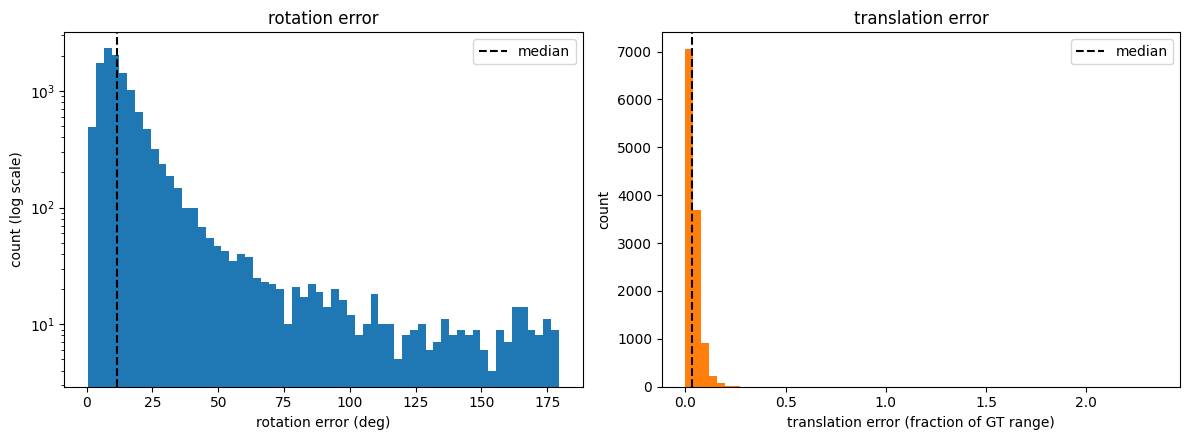

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(df["rotation_error_deg"], bins=60, color="tab:blue")
axes[0].axvline(df["rotation_error_deg"].median(), color="black", linestyle="--", label="median")
axes[0].set_yscale("log")
axes[0].set_xlabel("rotation error (deg)")
axes[0].set_ylabel("count (log scale)")
axes[0].set_title("rotation error")
axes[0].legend()

axes[1].hist(df["translation_error"], bins=60, color="tab:orange")
axes[1].axvline(df["translation_error"].median(), color="black", linestyle="--", label="median")
axes[1].set_xlabel("translation error (fraction of GT range)")
axes[1].set_ylabel("count")
axes[1].set_title("translation error")
axes[1].legend()

fig.tight_layout()

## Error vs range

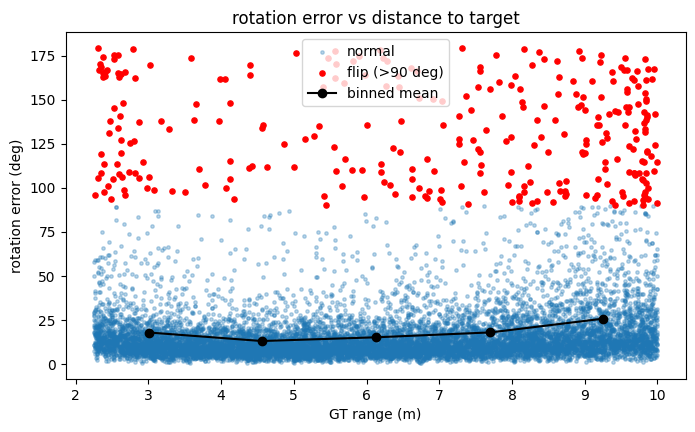

In [5]:
fig, ax = plt.subplots()

normal = df[~df["is_flip"]]
flips = df[df["is_flip"]]
ax.scatter(normal["gt_range_m"], normal["rotation_error_deg"], s=6, alpha=0.3, label="normal")
ax.scatter(flips["gt_range_m"], flips["rotation_error_deg"], s=14, color="red", label=f"flip (>{FLIP_THRESHOLD_DEG:.0f} deg)")

# binned mean, same bins as scripts/analyze_errors.py
num_bins = 5
df["range_bin"] = pd.qcut(df["gt_range_m"], num_bins)
binned = df.groupby("range_bin", observed=True)["rotation_error_deg"].mean()
bin_centers = [interval.mid for interval in binned.index]
ax.plot(bin_centers, binned.values, color="black", marker="o", label="binned mean")

ax.set_xlabel("GT range (m)")
ax.set_ylabel("rotation error (deg)")
ax.set_title("rotation error vs distance to target")
ax.legend()

## Worst cases

In [6]:
df.sort_values("rotation_error_deg", ascending=False).head(15)[
    ["filename", "rotation_error_deg", "translation_error", "gt_range_m",
     "q_gt_w", "q_gt_x", "q_gt_y", "q_gt_z", "q_pred_w", "q_pred_x", "q_pred_y", "q_pred_z"]
]

,filename,rotation_error_deg,translation_error,gt_range_m,q_gt_w,q_gt_x,q_gt_y,q_gt_z,q_pred_w,q_pred_x,q_pred_y,q_pred_z
7205,img036056.jpg,179.459030,0.039142,7.308166,-0.657390,-0.106113,0.743421,0.062472,-0.167725,0.447843,-0.016955,-0.878076
8130,img040921.jpg,179.183502,0.118815,2.306210,0.002572,0.021443,0.988675,-0.148509,-0.100419,-0.992558,0.037660,0.057681
6493,img032408.jpg,178.769440,0.031729,2.789911,0.261909,-0.630605,-0.727354,0.068540,0.052822,-0.740715,0.658140,0.124108
8456,img042483.jpg,178.679398,0.052144,8.159321,0.525319,-0.037985,-0.688171,0.499016,-0.030610,-0.216261,-0.569375,-0.792532
6075,img030363.jpg,178.108734,0.031326,6.191911,-0.191071,-0.787027,-0.585808,0.030145,-0.233961,-0.189635,0.312902,-0.900774
7935,img039906.jpg,178.012390,0.076385,5.565296,0.285768,0.649838,0.704079,0.017883,0.136467,-0.706305,0.628644,-0.295495
9376,img046952.jpg,177.593246,0.095920,8.918109,-0.472514,0.523887,0.446675,0.550231,0.472889,-0.459255,0.673223,0.335011
8352,img041957.jpg,177.302719,0.013807,8.377359,-0.159099,0.704006,0.600868,0.343541,0.331368,-0.578040,0.736146,0.118976
10408,img052009.jpg,176.575790,0.021898,5.036437,0.106505,0.826087,0.546093,0.089547,-0.024222,-0.520668,0.852718,-0.034499
9105,img045590.jpg,175.541870,0.085897,2.582179,-0.614349,-0.532126,0.540062,-0.218518,0.532934,-0.340180,0.559798,0.535617


## GT vs predicted overlay

Ground-truth (solid) and predicted (dashed) axis triads projected onto the worst images. X = red, Y = green, Z = blue. This separates a near-symmetric flip, where the predicted triad is the true one rotated about the body, from a prediction that is simply wrong.

In [7]:
import cv2

from tumbleweed.data.camera import load_camera
from tumbleweed.geometry.projection import axis_points, draw_pose, project_points

camera = load_camera(DATA_ROOT / "camera.json")
image_dir = DATA_ROOT / DOMAIN / "images"


def overlay_gt_and_pred(row: pd.Series, axis_length: float = 0.5) -> np.ndarray:
    """Project GT (solid) + predicted (dashed) axis triads onto one CSV row's image, as RGB."""
    image_path = image_dir / row["filename"]
    image = cv2.imread(str(image_path))
    if image is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")

    points_body, colors = axis_points(length=axis_length)

    q_gt = row[["q_gt_w", "q_gt_x", "q_gt_y", "q_gt_z"]].to_numpy(dtype=np.float64)
    t_gt = row[["t_gt_x", "t_gt_y", "t_gt_z"]].to_numpy(dtype=np.float64)
    q_pred = row[["q_pred_w", "q_pred_x", "q_pred_y", "q_pred_z"]].to_numpy(dtype=np.float64)
    t_pred = row[["t_pred_x", "t_pred_y", "t_pred_z"]].to_numpy(dtype=np.float64)

    gt_2d = project_points(points_body, q_gt, t_gt, camera)
    pred_2d = project_points(points_body, q_pred, t_pred, camera)

    out = draw_pose(image, gt_2d, colors)
    out = draw_pose(out, pred_2d, colors, dashed=True, origin_color=None)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

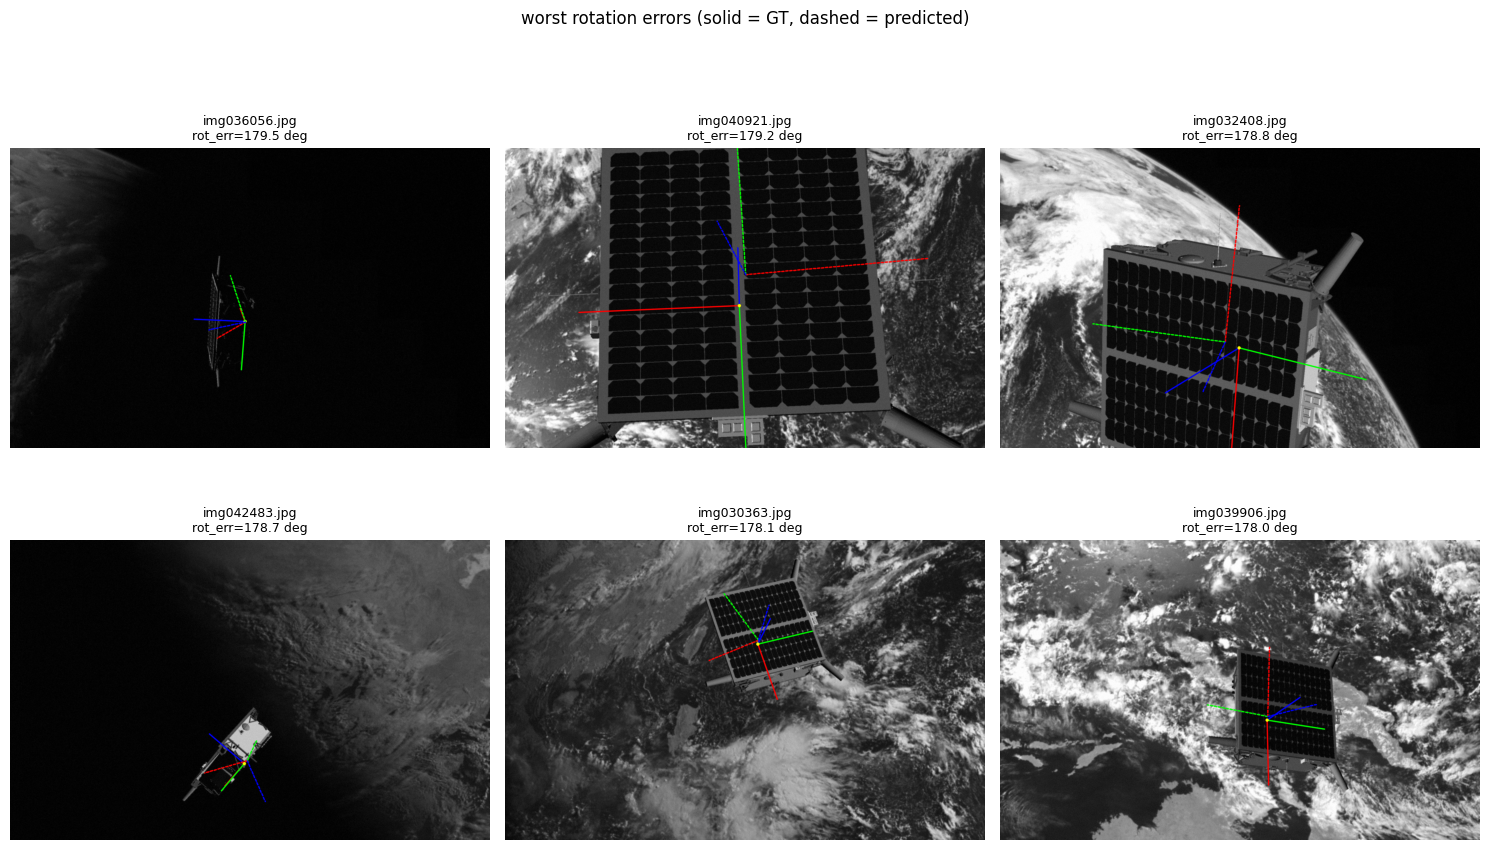

In [8]:
N_WORST = 6
worst_rows = df.sort_values("rotation_error_deg", ascending=False).head(N_WORST)

ncols = 3
nrows = int(np.ceil(N_WORST / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.5 * nrows))
axes = np.atleast_1d(axes).flatten()

for ax, (_, row) in zip(axes, worst_rows.iterrows()):
    ax.imshow(overlay_gt_and_pred(row))
    ax.set_title(f"{row['filename']}\nrot_err={row['rotation_error_deg']:.1f} deg", fontsize=9)
    ax.axis("off")

for ax in axes[len(worst_rows):]:
    ax.axis("off")

fig.suptitle("worst rotation errors (solid = GT, dashed = predicted)", y=1.02)
fig.tight_layout()

## Training curves

Per-epoch validation metrics from `checkpoints/metrics.csv`.

In [9]:
if not METRICS_CSV.exists():
    print(f"{METRICS_CSV} not found")
    epochs_df = None
else:
    epochs_df = pd.read_csv(METRICS_CSV)
    display(epochs_df)

,epoch,train_loss,num_samples,mean_translation_error,median_translation_error,std_translation_error,p90_translation_error,p95_translation_error,mean_rotation_error_deg,median_rotation_error_deg,std_rotation_error_deg,p90_rotation_error_deg,p95_rotation_error_deg,flip_rate_90deg,mean_speed_score
0,1,1.495299,11994,0.098357,0.081298,0.076946,0.187193,0.234729,45.433903,31.952093,38.449348,102.877739,140.129242,0.125229,0.891328
1,2,0.812295,11994,0.060991,0.050686,0.052297,0.111860,0.140072,32.289310,21.514734,31.464262,68.788750,105.832848,0.067200,0.624546
2,3,0.724515,11994,0.053800,0.042168,0.053613,0.101760,0.131233,29.181158,20.365580,28.170748,58.515968,90.377258,0.050359,0.563107
3,4,0.671511,11994,0.054211,0.042690,0.055863,0.102009,0.127408,27.196468,19.138323,26.571253,52.834427,81.735832,0.041604,0.528879
4,5,0.615792,11994,0.053792,0.043339,0.046353,0.101618,0.127717,31.115204,21.932037,29.205212,62.994904,94.782387,0.054694,0.596855
5,6,0.634234,11994,0.059870,0.046112,0.056261,0.117014,0.150650,30.873974,21.469826,29.544338,62.127460,96.581268,0.056278,0.598722
6,7,0.605381,11994,0.050710,0.041862,0.040793,0.097273,0.119463,25.661253,18.494398,25.004299,48.256794,72.887360,0.035351,0.498583
7,8,0.573207,11994,0.045517,0.035976,0.047148,0.086627,0.109974,23.743841,15.966460,25.719204,45.465828,73.200699,0.036685,0.459925
8,9,0.567747,11994,0.055451,0.046122,0.042069,0.106327,0.129141,26.983572,18.758732,27.388552,52.356365,81.312370,0.042855,0.526404
9,10,0.549644,11994,0.049823,0.041045,0.044333,0.095252,0.115874,22.748760,15.809451,24.612617,41.867702,66.446114,0.031849,0.446864


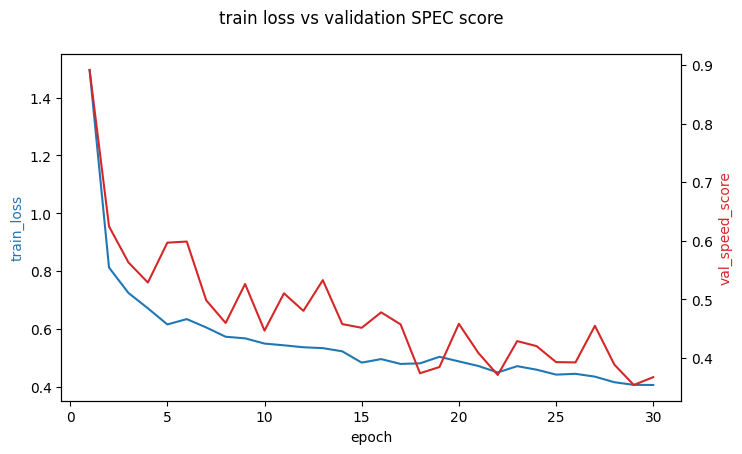

In [10]:
if epochs_df is not None:
    fig, ax1 = plt.subplots()
    ax1.plot(epochs_df["epoch"], epochs_df["train_loss"], color="tab:blue", label="train_loss")
    ax1.set_xlabel("epoch")
    ax1.set_ylabel("train_loss", color="tab:blue")

    ax2 = ax1.twinx()
    ax2.plot(epochs_df["epoch"], epochs_df["mean_speed_score"], color="tab:red", label="val_speed_score")
    ax2.set_ylabel("val_speed_score", color="tab:red")

    fig.suptitle("train loss vs validation SPEC score")

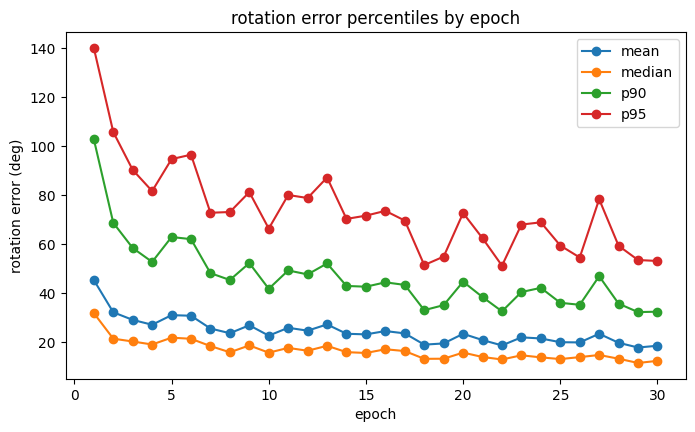

In [11]:
if epochs_df is not None:
    fig, ax = plt.subplots()
    for col, label in [
        ("mean_rotation_error_deg", "mean"),
        ("median_rotation_error_deg", "median"),
        ("p90_rotation_error_deg", "p90"),
        ("p95_rotation_error_deg", "p95"),
    ]:
        ax.plot(epochs_df["epoch"], epochs_df[col], marker="o", label=label)
    ax.set_xlabel("epoch")
    ax.set_ylabel("rotation error (deg)")
    ax.set_title("rotation error percentiles by epoch")
    ax.legend()

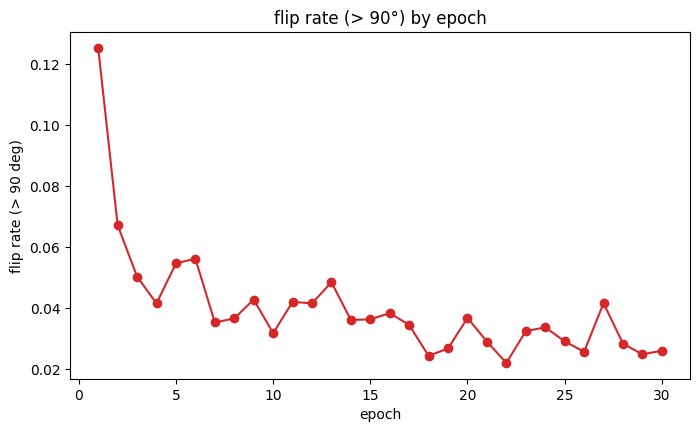

In [12]:
if epochs_df is not None:
    fig, ax = plt.subplots()
    ax.plot(epochs_df["epoch"], epochs_df["flip_rate_90deg"], marker="o", color="tab:red")
    ax.set_xlabel("epoch")
    ax.set_ylabel("flip rate (> 90 deg)")
    ax.set_title("flip rate (> 90°) by epoch")

## Summary

- Translation is good: the median error is 3.4% of range, enough to locate the spacecraft in the frame.
- Rotation is the weak part. The median error is 11.6°, but the tail is long (p95 53.6°) and 2.5% of predictions are off by more than 90°.
- Validation scores have been roughly flat since about epoch 18, so training this model longer won't close the gap.

One pooled feature vector has to encode the full rotation, and near-symmetric views of Tango map to very different quaternions. That is the motivation for keypoints + PnP: the network only localizes points in the image, and the geometry recovers the rotation.